# Astana Apartment Price Prediction
**Machine Learning Algorithms: Midterm Project**

Team: *Nurkhan Kuanyshov and Bakytzhan Jangazy*
Group: *SE-2431*

## 1. Problem statement
- **Question:** predict the asking price of an apartment in Astana from its area, location, floor, age and amenities.
- **Task type:** regression.
- **Target:** `price` (we model `log1p(price)` because prices are right-skewed).
- **Metrics:** RMSE, MAE and R² (on the log scale), plus MAE and median absolute percentage error in tenge.
- **Success criterion:** every model must clearly beat the baseline (predicting the median); target for the best model is a median error of about 15% or lower.

## 2. Dataset
- **Source:** Kaggle, *Astana Real Estate Dataset* by `turarr` (https://www.kaggle.com/datasets/turarr/astana-real-estate-dataset). Ads scraped from Krisha.kz, data current as of end of March 2026.
- **Known issues:** these are asking prices (not final sale prices), ads can be duplicated, values are typed by sellers (typos, outliers), some columns have many missing values.

In [1]:
import re
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, KFold, cross_val_score, GridSearchCV, validation_curve
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

# ---- settings: change only this block ----
DATA_PATH = "astana_real_estate_dataset.csv"   # path to the full CSV from Kaggle
TARGET = "price"
RANDOM_STATE = 42
CURRENT_YEAR = 2026

## 3. Data loading and first look

In [2]:
df_raw = pd.read_csv(DATA_PATH)
df = df_raw.copy()

print("Shape:", df.shape)
df.head()

Shape: (5003, 23)


,url,title,price,security,ceiling_height,Год постройки,district,residential_complex,furnished,parking,bathroom_type,apartment_condition,building_type,rooms,current_floor,total_floors,area_m2,address,district_lat,district_lon,apartment_lat,apartment_lon,coord_level
0,https://krisha.kz/a/show/683656844,"3-комнатная квартира · 120 м², Сыганак — Кабан...",55000000,"домофон, видеонаблюдение",2.902672,2006,"Есильский район, Астана, Казахстан",7 Бочек,полностью,Во дворе/не указано,2 с/у и более,свежий ремонт,монолитный,3.0,6.0,11.0,120.00,Сыганак — Кабанбай батыра,51.120,71.430,51.122041,71.413101,Address
1,https://krisha.kz/a/show/1010380882,"2-комнатная квартира · 64.5 м² · 9/9 этаж, Тол...",45500000,"домофон, видеонаблюдение",3.000000,2022,"Нуринский район, Астана, Казахстан",Dastur,полностью,Во дворе/не указано,совмещенный,Не указано,кирпичный,2.0,9.0,9.0,64.50,Толе би 25,51.100,71.380,51.099779,71.389694,Complex
2,https://krisha.kz/a/show/1010251370,"2-комнатная квартира · 64.37 м² · 10/12 этаж, ...",32800000,"домофон, кодовый замок, видеодомофон",3.000000,2026,"Сарыаркинский район, Астана, Казахстан",Shalqar,без мебели,паркинг,совмещенный,черновая отделка,кирпичный,2.0,10.0,12.0,64.37,Чингиз Айтматов 77/11 — Мечеть Ырыскелді Кажы,51.170,71.410,51.170000,71.410000,District
3,https://krisha.kz/a/show/1010195327,"3-комнатная квартира · 115 м², Ивана Панфилова 85",75000000,"домофон, видеонаблюдение",3.200000,2026,"Сарыаркинский район, Астана, Казахстан",TANSU,без мебели,паркинг,совмещенный,Не указано,кирпичный,3.0,6.0,11.0,115.00,Ивана Панфилова 85,51.117,71.565,51.105860,71.500377,Complex
4,https://krisha.kz/a/show/1009176178,"2-комнатная квартира · 52 м² · 8/12 этаж, Кубр...",25000000,"домофон, видеонаблюдение",2.700000,2009,"Сарыаркинский район, Астана, Казахстан",Сайран,полностью,Во дворе/не указано,совмещенный,свежий ремонт,кирпичный,2.0,8.0,12.0,52.00,Кубрина 20/1,51.170,71.410,51.197097,71.475239,Complex


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5003 entries, 0 to 5002
Data columns (total 23 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   url                  5003 non-null   object 
 1   title                5003 non-null   object 
 2   price                5003 non-null   int64  
 3   security             5003 non-null   object 
 4   ceiling_height       5003 non-null   float64
 5   Год постройки        5003 non-null   int64  
 6   district             5003 non-null   object 
 7   residential_complex  5003 non-null   object 
 8   furnished            5003 non-null   object 
 9   parking              5003 non-null   object 
 10  bathroom_type        5003 non-null   object 
 11  apartment_condition  5003 non-null   object 
 12  building_type        5003 non-null   object 
 13  rooms                5003 non-null   float64
 14  current_floor        5003 non-null   float64
 15  total_floors         5003 non-null   f

In [4]:
print("Missing values (share of rows):")
print((df.isna().mean().sort_values(ascending=False) * 100).round(1).to_string())
print("\nDuplicated rows:", df.duplicated().sum())
df.describe(include="all").T

Missing values (share of rows):
url                    0.0
building_type          0.0
apartment_lon          0.0
apartment_lat          0.0
district_lon           0.0
district_lat           0.0
address                0.0
area_m2                0.0
total_floors           0.0
current_floor          0.0
rooms                  0.0
apartment_condition    0.0
title                  0.0
bathroom_type          0.0
parking                0.0
furnished              0.0
residential_complex    0.0
district               0.0
Год постройки          0.0
ceiling_height         0.0
security               0.0
price                  0.0
coord_level            0.0

Duplicated rows: 829


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
url,5003,4174,https://krisha.kz/a/show/683656844,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
title,5003,4165,"3-комнатная квартира · 120 м², Сыганак — Кабан...",3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
price,5003.0,NaN,NaN,NaN,54132514.681391,479861309.406489,3500000.0,27500000.0,37800000.0,55000000.0,33900000000.0
security,5003,123,"домофон, видеонаблюдение",3176,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ceiling_height,5003.0,NaN,NaN,NaN,2.902672,0.51158,1.8,2.7,3.0,3.0,27.0
Год постройки,5003.0,NaN,NaN,NaN,2019.018389,9.713574,1959.0,2017.0,2022.0,2025.0,2028.0
district,5003,6,"Нуринский район, Астана, Казахстан",1486,NaN,NaN,NaN,NaN,NaN,NaN,NaN
residential_complex,5003,902,Панельный дом/Не указан,698,NaN,NaN,NaN,NaN,NaN,NaN,NaN
furnished,5003,3,без мебели,2509,NaN,NaN,NaN,NaN,NaN,NaN,NaN
parking,5003,4,паркинг,2928,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 4. Data cleaning
Every step prints what was found and what was done:
1. convert text columns that actually contain numbers (e.g. `"45 000 000 〒"`) to numeric;
2. split `"5 из 9"`-like columns into floor and total floors;
3. drop identifiers/text columns, columns with too many missing values, and any other price-like column (it would leak the target);
4. remove duplicates, rows without a price and unrealistic values.

In [5]:
def to_number(s):
    """'45 000 000 〒' -> 45000000.0, '2,7 м' -> 2.7"""
    s = s.astype(str).str.replace(r"[^\d.,-]", "", regex=True).str.replace(",", ".", regex=False)
    return pd.to_numeric(s, errors="coerce")

# 1) target must be numeric
if not pd.api.types.is_numeric_dtype(df[TARGET]):
    df[TARGET] = to_number(df[TARGET])
df = df.dropna(subset=[TARGET])
df = df[df[TARGET] > 0]

# 2) "5 из 9" style columns -> floor + floors_total
pat = re.compile(r"^\s*(\d+)\s*(?:из|/)\s*(\d+)\s*$")
for col in [c for c in df.columns if not pd.api.types.is_numeric_dtype(df[c]) and not pd.api.types.is_bool_dtype(df[c])]:
    m = df[col].astype(str).str.extract(pat)
    if m[0].notna().mean() > 0.5:
        df["floor"] = pd.to_numeric(m[0])
        df["floors_total"] = pd.to_numeric(m[1])
        df = df.drop(columns=col)
        print(f"Split '{col}' into floor and floors_total")

# 3) object columns that are really numeric
for col in [c for c in df.columns if not pd.api.types.is_numeric_dtype(df[c]) and not pd.api.types.is_bool_dtype(df[c]) and c != TARGET]:
    parsed = to_number(df[col])
    non_null = df[col].notna().sum()
    if non_null > 0 and parsed.notna().sum() >= 0.9 * non_null:
        df[col] = parsed
        print(f"Converted '{col}' to numeric")

# 4) columns to drop
drop = []
id_like = re.compile(r"url|link|title|descr|phone|(^|_)id$", re.I)
for col in df.columns:
    if col == TARGET:
        continue
    if id_like.search(col):
        drop.append(col); print(f"Drop '{col}': identifier / free text")
    elif not pd.api.types.is_numeric_dtype(df[col]) and df[col].nunique() > 0.5 * len(df):
        drop.append(col); print(f"Drop '{col}': almost unique text values")
    elif df[col].isna().mean() > 0.6:
        drop.append(col); print(f"Drop '{col}': more than 60% missing")
    elif "price" in col.lower() or "цен" in col.lower():
        drop.append(col); print(f"Drop '{col}': price-like column, would leak the target")
df = df.drop(columns=drop)

# 5) duplicates
before = len(df)
df = df.drop_duplicates()
print(f"Removed {before - len(df)} duplicated rows")
print("Shape after basic cleaning:", df.shape)

Converted 'url' to numeric
Drop 'url': identifier / free text
Drop 'title': identifier / free text
Drop 'address': almost unique text values
Removed 834 duplicated rows
Shape after basic cleaning: (4169, 20)


### Detect key columns
The code looks for area, rooms and build-year columns by name. **Check the printout** and set them manually if something is wrong or `None`.

In [6]:
def find_col(pattern, numeric=True, exclude=()):
    cols = df.select_dtypes(include="number").columns if numeric else df.columns
    for c in cols:
        if c != TARGET and c not in exclude and re.search(pattern, c, re.I):
            return c
    return None

# Prefer exact dataset columns when they exist. This avoids accidental matches such as
# treating total_floors as area just because it contains the word "total".
AREA_COL = "area_m2" if "area_m2" in df.columns else find_col(r"area|площад|sq")
ROOMS_COL = "rooms" if "rooms" in df.columns else find_col(r"room|комнат")
YEAR_COL = "Год постройки" if "Год постройки" in df.columns else find_col(r"year|год")
FLOOR_COL = "current_floor" if "current_floor" in df.columns else find_col(r"(^|_)floor$|этаж")
TOTAL_FLOORS_COL = "total_floors" if "total_floors" in df.columns else find_col(r"total_floors|floors_total|этажность", exclude={FLOOR_COL})
DISTRICT_COL = "district" if "district" in df.columns else find_col(r"district|район", numeric=False)

print("AREA_COL         =", AREA_COL)
print("ROOMS_COL        =", ROOMS_COL)
print("YEAR_COL         =", YEAR_COL)
print("FLOOR_COL        =", FLOOR_COL)
print("TOTAL_FLOORS_COL =", TOTAL_FLOORS_COL)
print("DISTRICT_COL     =", DISTRICT_COL)

AREA_COL         = area_m2
ROOMS_COL        = rooms
YEAR_COL         = Год постройки
FLOOR_COL        = current_floor
TOTAL_FLOORS_COL = total_floors
DISTRICT_COL     = district


In [7]:
# realistic ranges (documented sanity rules)
n0 = len(df)
if AREA_COL:
    df = df[df[AREA_COL].between(10, 500)]
if ROOMS_COL:
    df = df[df[ROOMS_COL].between(1, 10)]
if YEAR_COL:
    df.loc[~df[YEAR_COL].between(1900, CURRENT_YEAR + 3), YEAR_COL] = np.nan
if FLOOR_COL and TOTAL_FLOORS_COL:
    df = df[df[FLOOR_COL].between(1, 60)]
    df = df[df[TOTAL_FLOORS_COL].between(1, 80)]
    df = df[df[FLOOR_COL] <= df[TOTAL_FLOORS_COL]]
if "ceiling_height" in df.columns:
    df.loc[~df["ceiling_height"].between(2.0, 6.0), "ceiling_height"] = np.nan

# price outliers: keep 1st-99th percentile
lo, hi = df[TARGET].quantile([0.01, 0.99])
df = df[df[TARGET].between(lo, hi)]
print(f"Removed {n0 - len(df)} rows with unrealistic values or extreme prices")
print(f"Price range kept: {lo:,.0f} - {hi:,.0f}")
print("Final shape:", df.shape)

Removed 83 rows with unrealistic values or extreme prices
Price range kept: 13,466,000 - 185,000,000
Final shape: (4086, 20)


## 5. Exploratory data analysis
The EDA below checks target skew, the relationship between area and price, district-level price differences, numeric correlations, and remaining missing values. Each plot is followed by a short interpretation.

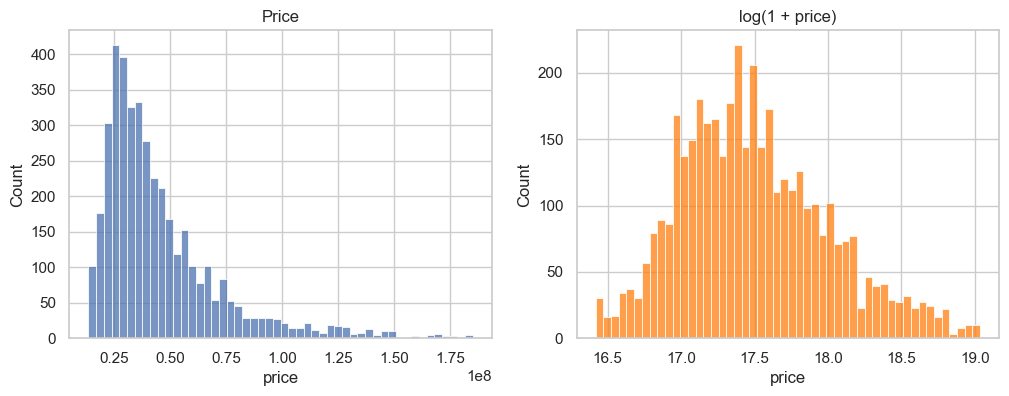

Skewness raw: 1.95 | log: 0.5


In [8]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df[TARGET], bins=50, ax=ax[0]); ax[0].set_title("Price")
sns.histplot(np.log1p(df[TARGET]), bins=50, ax=ax[1], color="tab:orange"); ax[1].set_title("log(1 + price)")
plt.show()
print("Skewness raw:", round(df[TARGET].skew(), 2), "| log:", round(np.log1p(df[TARGET]).skew(), 2))

**Interpretation.** Apartment prices are strongly right-skewed: most listings are in the lower and middle price ranges, while a smaller number of premium listings creates a long tail. The `log1p(price)` transformation makes the target distribution more symmetric, which is better for regression models.

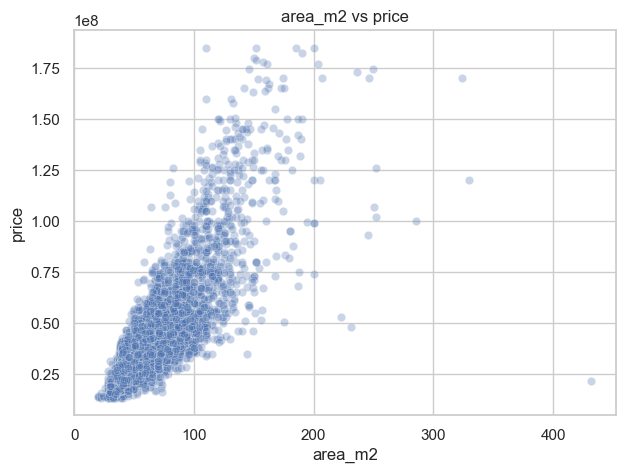

In [9]:
if AREA_COL:
    plt.figure(figsize=(7, 5))
    sns.scatterplot(data=df, x=AREA_COL, y=TARGET, alpha=0.3)
    plt.title(f"{AREA_COL} vs price"); plt.show()

**Interpretation.** Area has a clear positive relationship with price: larger apartments generally cost more. The spread also increases for larger apartments, so area alone is not enough and location/quality features are still needed.

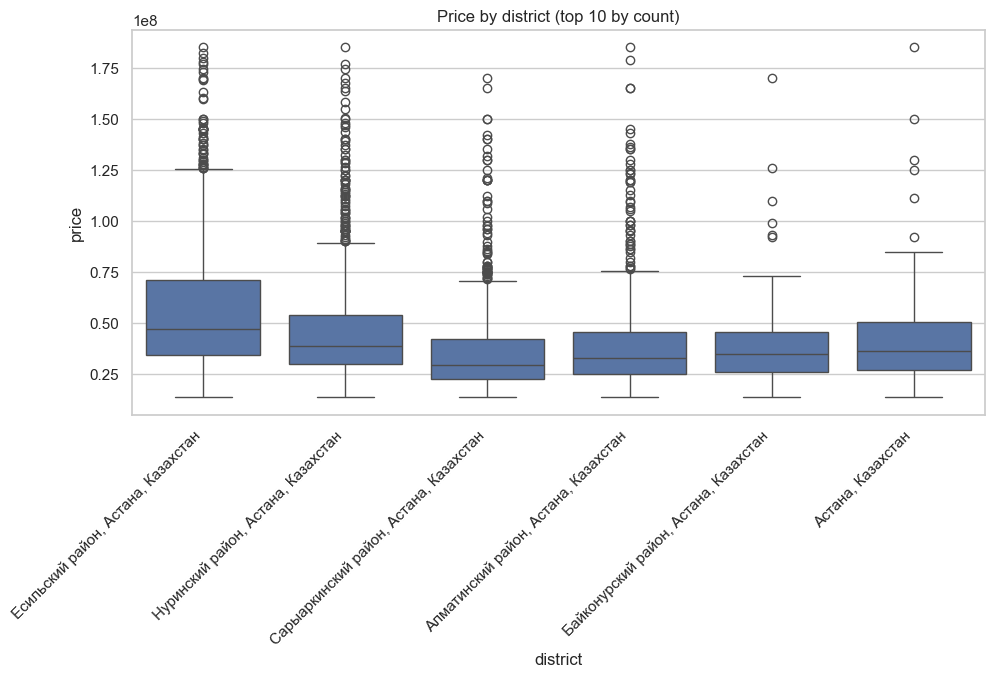

In [10]:
if DISTRICT_COL:
    top = df[DISTRICT_COL].value_counts().head(10).index
    plt.figure(figsize=(11, 5))
    sns.boxplot(data=df[df[DISTRICT_COL].isin(top)], x=DISTRICT_COL, y=TARGET)
    plt.xticks(rotation=45, ha="right"); plt.title("Price by district (top 10 by count)"); plt.show()

**Interpretation.** Districts differ in both median price and variability. This supports keeping district as a categorical feature because location carries useful signal for apartment prices.

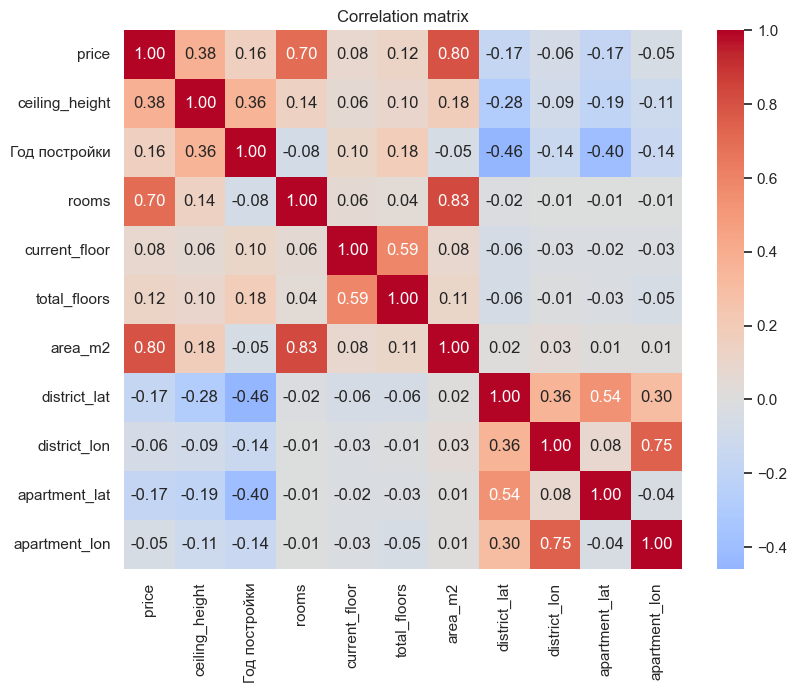

In [11]:
num = df.select_dtypes(include="number")
plt.figure(figsize=(9, 7))
sns.heatmap(num.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation matrix"); plt.show()

**Interpretation.** The correlation matrix helps identify the strongest numeric relationships and possible redundancy. Area, number of rooms, floor information, coordinates, and building age are checked before modelling so that the feature set is understandable.

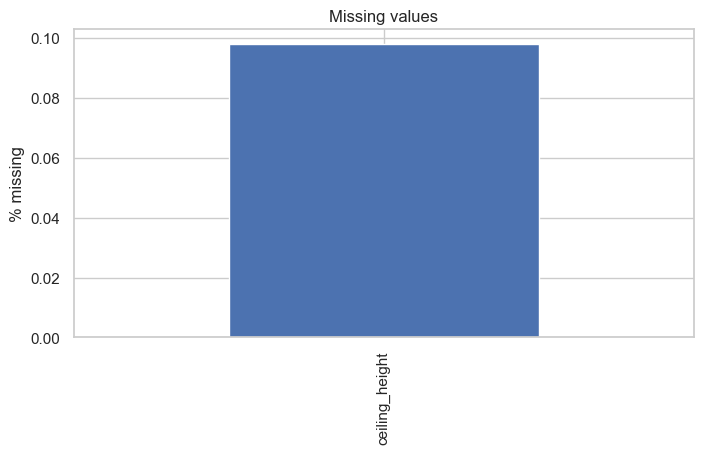

In [12]:
miss = (df.isna().mean() * 100).sort_values(ascending=False)
miss = miss[miss > 0]
if len(miss):
    plt.figure(figsize=(8, 4)); miss.plot.bar(); plt.ylabel("% missing"); plt.title("Missing values"); plt.show()
else:
    print("No missing values left")

**Interpretation.** Missing-value analysis confirms what must be handled by the preprocessing pipeline. Numeric values are imputed with medians and categorical values with the most frequent category inside the model pipeline, preventing leakage from validation/test data.

## 6. Feature engineering
New features (each one is justified):
- `house_age` = current year - build year (age is more meaningful than the raw year);
- `is_first_floor`, `is_last_floor` (first and last floors are usually cheaper or more specific market segments);
- `floor_ratio` = current floor / total floors;
- `area_per_room` = area / rooms.

Scaling and one-hot encoding are done later **inside the pipeline**, so they are fitted on the training data only.

In [13]:
if YEAR_COL:
    df["house_age"] = CURRENT_YEAR - df[YEAR_COL]
    df = df.drop(columns=YEAR_COL)
if FLOOR_COL and TOTAL_FLOORS_COL:
    df["is_first_floor"] = (df[FLOOR_COL] == 1).astype(int)
    df["is_last_floor"] = (df[FLOOR_COL] == df[TOTAL_FLOORS_COL]).astype(int)
    df["floor_ratio"] = df[FLOOR_COL] / df[TOTAL_FLOORS_COL].replace(0, np.nan)
if AREA_COL and ROOMS_COL:
    df["area_per_room"] = df[AREA_COL] / df[ROOMS_COL]

# target on log scale
y = np.log1p(df[TARGET])
X = df.drop(columns=TARGET)
print("Features:", list(X.columns))

Features: ['security', 'ceiling_height', 'district', 'residential_complex', 'furnished', 'parking', 'bathroom_type', 'apartment_condition', 'building_type', 'rooms', 'current_floor', 'total_floors', 'area_m2', 'district_lat', 'district_lon', 'apartment_lat', 'apartment_lon', 'coord_level', 'house_age', 'is_first_floor', 'is_last_floor', 'floor_ratio', 'area_per_room']


## 7. Train / validation / test split and leakage control
- Split **70 / 15 / 15** with a fixed seed, done **before** any imputation, scaling or encoding.
- Imputer, scaler and encoder live inside a `Pipeline`, so they learn only from the training part (and from the training folds during cross-validation).
- Price-like columns (e.g. price per m²) were removed because they are computed from the target.
- The test set is used **once**, at the very end, for the final model.

In [14]:
# For a regression target, stratification is approximated with quantile bins of the log-price.
# This keeps cheap/mid/expensive apartments represented in train, validation and test splits.
price_bins = pd.qcut(y, q=10, labels=False, duplicates="drop")
X_train, X_tmp, y_train, y_tmp, bins_train, bins_tmp = train_test_split(
    X, y, price_bins, test_size=0.30, random_state=RANDOM_STATE, stratify=price_bins
)
X_val, X_test, y_val, y_test = train_test_split(
    X_tmp, y_tmp, test_size=0.50, random_state=RANDOM_STATE, stratify=bins_tmp
)
print("train:", X_train.shape, "| val:", X_val.shape, "| test:", X_test.shape)

train: (2860, 23) | val: (613, 23) | test: (613, 23)


In [15]:
num_cols = X_train.select_dtypes(include="number").columns.tolist()
cat_cols = X_train.select_dtypes(exclude="number").columns.tolist()
print("Numeric:", num_cols)
print("Categorical:", cat_cols)

def make_preprocessor():
    num_pipe = Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())])
    cat_pipe = Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                         ("oh", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=10, sparse_output=False))])
    return ColumnTransformer([("num", num_pipe, num_cols), ("cat", cat_pipe, cat_cols)])

def make_pipe(model):
    return Pipeline([("prep", make_preprocessor()), ("model", model)])

Numeric: ['ceiling_height', 'rooms', 'current_floor', 'total_floors', 'area_m2', 'district_lat', 'district_lon', 'apartment_lat', 'apartment_lon', 'house_age', 'is_first_floor', 'is_last_floor', 'floor_ratio', 'area_per_room']
Categorical: ['security', 'district', 'residential_complex', 'furnished', 'parking', 'bathroom_type', 'apartment_condition', 'building_type', 'coord_level']


## 8. Baseline and models
- **Baseline:** always predicts the median log-price.
- **Linear Regression**, **Decision Tree Regressor**, **KNN Regressor** (scaling is done in the pipeline, which KNN needs).

In [16]:
def evaluate(y_true_log, y_pred_log):
    rmse = np.sqrt(mean_squared_error(y_true_log, y_pred_log))
    mae = mean_absolute_error(y_true_log, y_pred_log)
    r2 = r2_score(y_true_log, y_pred_log)
    t, p = np.expm1(y_true_log), np.expm1(y_pred_log)
    return {"RMSE_log": rmse, "MAE_log": mae, "R2": r2,
            "MAE_KZT": mean_absolute_error(t, p),
            "MedAPE_%": float(np.median(np.abs(t - p) / t) * 100)}

models = {
    "Baseline (median)": DummyRegressor(strategy="median"),
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(max_depth=8, min_samples_leaf=10, random_state=RANDOM_STATE),
    "KNN": KNeighborsRegressor(n_neighbors=7, weights="distance"),
}

rows = []
for name, m in models.items():
    pipe = make_pipe(m).fit(X_train, y_train)
    for split, (Xs, ys) in {"train": (X_train, y_train), "val": (X_val, y_val)}.items():
        rows.append({"model": name, "split": split, **evaluate(ys, pipe.predict(Xs))})
results = pd.DataFrame(rows)
results.pivot(index="model", columns="split", values=["RMSE_log", "R2", "MedAPE_%"]).round(3)

RMSE_log            R2        MedAPE_%        
split                train    val  train    val    train     val
model                                                           
Baseline (median)    0.510  0.500 -0.013 -0.013   33.882  33.929
Decision Tree        0.167  0.216  0.891  0.810    9.756  12.546
KNN                  0.000  0.225  1.000  0.796    0.000  13.478
Linear Regression    0.203  0.191  0.840  0.853   11.359  11.246

In [17]:
results[results.split == "val"].set_index("model").drop(columns="split").round(3)

,RMSE_log,MAE_log,R2,MAE_KZT,MedAPE_%
model,,,,,
Baseline (median),0.500,0.398,-0.013,1.791594e+07,33.929
Linear Regression,0.191,0.146,0.853,7.079818e+06,11.246
Decision Tree,0.216,0.165,0.810,7.884648e+06,12.546
KNN,0.225,0.170,0.796,7.786939e+06,13.478


## 9. Cross-validation (5-fold, training data only)

In [18]:
kf = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_rows = []
for name, m in models.items():
    scores = -cross_val_score(make_pipe(m), X_train, y_train, cv=kf, scoring="neg_root_mean_squared_error")
    cv_rows.append({"model": name, "CV RMSE (log) mean": scores.mean(), "CV RMSE std": scores.std()})
pd.DataFrame(cv_rows).set_index("model").round(4)

,CV RMSE (log) mean,CV RMSE std
model,,
Baseline (median),0.5093,0.0132
Linear Regression,0.2188,0.0306
Decision Tree,0.2153,0.0151
KNN,0.2314,0.0086


## 10. Hyperparameter tuning (GridSearchCV on the training data)

In [19]:
tree_grid = GridSearchCV(
    make_pipe(DecisionTreeRegressor(random_state=RANDOM_STATE)),
    {"model__max_depth": [3, 5, 7, 9, 12, 15], "model__min_samples_leaf": [1, 5, 10, 20, 40]},
    cv=kf, scoring="neg_root_mean_squared_error", n_jobs=-1).fit(X_train, y_train)

knn_grid = GridSearchCV(
    make_pipe(KNeighborsRegressor()),
    {"model__n_neighbors": list(range(3, 31, 2)), "model__weights": ["uniform", "distance"],
     "model__metric": ["euclidean", "manhattan"]},
    cv=kf, scoring="neg_root_mean_squared_error", n_jobs=-1).fit(X_train, y_train)

print("Tree best:", tree_grid.best_params_, "CV RMSE:", round(-tree_grid.best_score_, 4))
print("KNN  best:", knn_grid.best_params_, "CV RMSE:", round(-knn_grid.best_score_, 4))

Tree best: {'model__max_depth': 12, 'model__min_samples_leaf': 10} CV RMSE: 0.2152
KNN  best: {'model__metric': 'euclidean', 'model__n_neighbors': 9, 'model__weights': 'distance'} CV RMSE: 0.2308


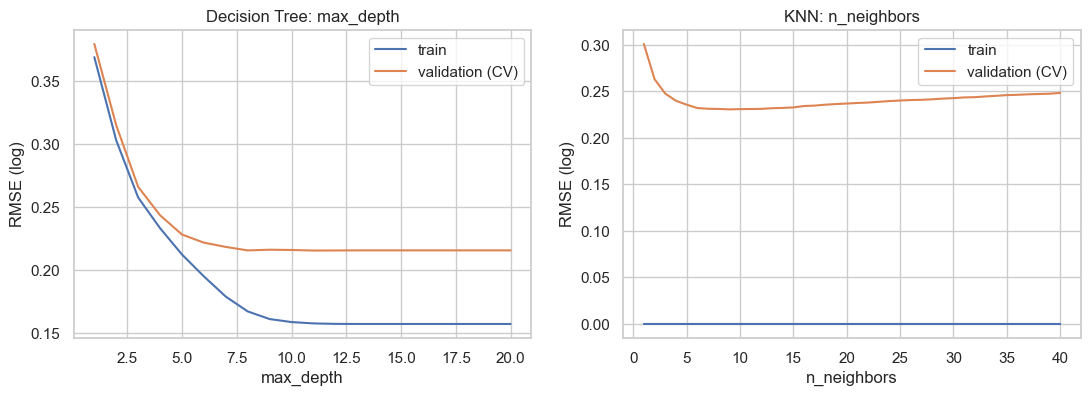

In [20]:
# validation curves: where does overfitting start?
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for a, (pipe, pname, rng, title) in zip(ax, [
    (make_pipe(DecisionTreeRegressor(min_samples_leaf=10, random_state=RANDOM_STATE)), "model__max_depth", range(1, 21), "Decision Tree: max_depth"),
    (make_pipe(KNeighborsRegressor(weights="distance")), "model__n_neighbors", range(1, 41), "KNN: n_neighbors"),
]):
    tr, va = validation_curve(pipe, X_train, y_train, param_name=pname, param_range=list(rng),
                              cv=kf, scoring="neg_root_mean_squared_error", n_jobs=-1)
    a.plot(list(rng), -tr.mean(1), label="train"); a.plot(list(rng), -va.mean(1), label="validation (CV)")
    a.set_title(title); a.set_xlabel(pname.split("__")[1]); a.set_ylabel("RMSE (log)"); a.legend()
plt.show()

In [21]:
final_models = {
    "Baseline (median)": make_pipe(DummyRegressor(strategy="median")).fit(X_train, y_train),
    "Linear Regression": make_pipe(LinearRegression()).fit(X_train, y_train),
    "Decision Tree (tuned)": tree_grid.best_estimator_,
    "KNN (tuned)": knn_grid.best_estimator_,
}
val_table = pd.DataFrame({n: evaluate(y_val, m.predict(X_val)) for n, m in final_models.items()}).T
val_table.round(3)

,RMSE_log,MAE_log,R2,MAE_KZT,MedAPE_%
Baseline (median),0.500,0.398,-0.013,1.791594e+07,33.929
Linear Regression,0.191,0.146,0.853,7.079818e+06,11.246
Decision Tree (tuned),0.218,0.164,0.808,8.019353e+06,12.797
KNN (tuned),0.221,0.168,0.802,7.666239e+06,13.441


## 11. Error analysis

Best model on validation: Linear Regression


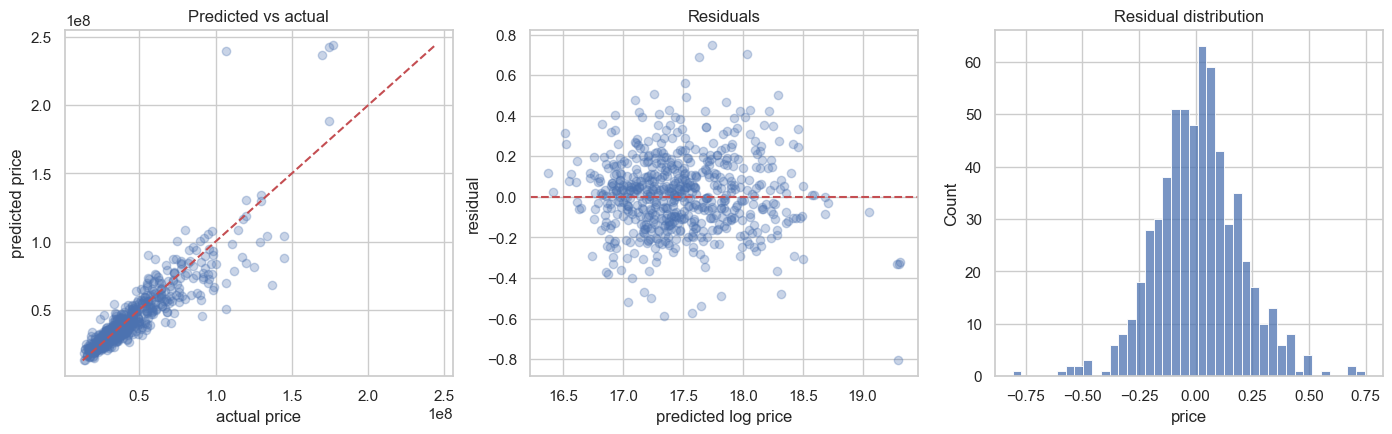

In [22]:
best_name = val_table["RMSE_log"].idxmin()
best = final_models[best_name]
print("Best model on validation:", best_name)

pred_val = best.predict(X_val)
true_p, pred_p = np.expm1(y_val), np.expm1(pred_val)
resid = np.log1p(true_p) - np.log1p(pred_p)

fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
ax[0].scatter(true_p, pred_p, alpha=0.3)
lims = [min(true_p.min(), pred_p.min()), max(true_p.max(), pred_p.max())]
ax[0].plot(lims, lims, "r--"); ax[0].set_xlabel("actual price"); ax[0].set_ylabel("predicted price"); ax[0].set_title("Predicted vs actual")
ax[1].scatter(pred_val, resid, alpha=0.3); ax[1].axhline(0, color="r", ls="--")
ax[1].set_xlabel("predicted log price"); ax[1].set_ylabel("residual"); ax[1].set_title("Residuals")
sns.histplot(resid, bins=40, ax=ax[2]); ax[2].set_title("Residual distribution")
plt.show()

In [23]:
err = pd.DataFrame({"actual": true_p.values, "pred": pred_p, "ape_%": np.abs(true_p.values - pred_p) / true_p.values * 100},
                   index=y_val.index)
err["price_bin"] = pd.qcut(err["actual"], 5, labels=["cheapest 20%", "low", "mid", "high", "top 20%"])
print("Median % error by price segment:")
print(err.groupby("price_bin")["ape_%"].median().round(1).to_string())

if DISTRICT_COL:
    err[DISTRICT_COL] = X_val[DISTRICT_COL]
    g = err.groupby(DISTRICT_COL)["ape_%"].agg(["median", "count"])
    print("\nMedian % error by district (at least 20 apartments):")
    print(g[g["count"] >= 20].sort_values("median").round(1).to_string())

print("\nLargest errors:")
err.sort_values("ape_%", ascending=False).head(10).round(1)

Median % error by price segment:
price_bin
cheapest 20%    10.5
low              9.7
mid             11.1
high            11.1
top 20%         15.0

Median % error by district (at least 20 apartments):
                                        median  count
district                                             
Астана, Казахстан                          7.8     20
Сарыаркинский район, Астана, Казахстан     9.7    117
Алматинский район, Астана, Казахстан      11.0    100
Нуринский район, Астана, Казахстан        11.5    183
Есильский район, Астана, Казахстан        12.8    169
Байконурский район, Астана, Казахстан     14.9     24

Largest errors:


,actual,pred,ape_%,price_bin,district
957,107000000.0,239729175.8,124.0,top 20%,"Есильский район, Астана, Казахстан"
575,18870000.0,34001488.6,80.2,cheapest 20%,"Нуринский район, Астана, Казахстан"
2808,24200000.0,42917647.0,77.3,cheapest 20%,"Есильский район, Астана, Казахстан"
1195,27000000.0,46202962.8,71.1,low,"Есильский район, Астана, Казахстан"
2188,15000000.0,25133746.3,67.6,cheapest 20%,"Есильский район, Астана, Казахстан"
3152,18500000.0,30513261.4,64.9,cheapest 20%,"Есильский район, Астана, Казахстан"
3334,33500000.0,54494575.5,62.7,mid,"Есильский район, Астана, Казахстан"
3509,56000000.0,90499685.2,61.6,high,"Нуринский район, Астана, Казахстан"
4417,18000000.0,28831844.2,60.2,cheapest 20%,"Есильский район, Астана, Казахстан"
3030,106990000.0,50694257.8,52.6,top 20%,"Есильский район, Астана, Казахстан"


## 12. Final evaluation on the test set (used once)

In [24]:
final = final_models[best_name].fit(pd.concat([X_train, X_val]), pd.concat([y_train, y_val]))
test_scores = evaluate(y_test, final.predict(X_test))
pd.Series(test_scores, name=f"{best_name} on TEST").round(3)

RMSE_log          0.205
MAE_log           0.155
R2                0.838
MAE_KZT     7524525.528
MedAPE_%         11.956
Name: Linear Regression on TEST, dtype: float64

## 13. Conclusions, open problems and plan for the final stage
**Conclusions.** After fixing the feature logic and using `area_m2` as the real apartment area, the project keeps 4,086 cleaned listings. The median baseline has validation RMSE_log = 0.500 and MedAPE = 33.9%, while Linear Regression achieves validation RMSE_log = 0.191, R² = 0.853 and MedAPE = 11.2%. On the held-out test set used once at the end, Linear Regression reaches RMSE_log = 0.205, R² = 0.838 and MedAPE = 12.0%, so it clearly beats the baseline and satisfies the midterm success criterion.

**Interpretation.** The most important signal is still apartment size and related engineered features, but district, residential complex, floor, age, coordinates and amenities improve prediction. Error analysis shows that the top 20% most expensive apartments are harder to predict: their median validation percentage error is about 15.0%, compared with around 9.7-11.1% for most middle price segments.

**Open problems**
- Asking prices are not final transaction prices, so the target includes seller expectations and negotiation margin.
- Some duplicated or near-duplicated advertisements may remain even after exact duplicate removal.
- Residential complex names are high-cardinality categorical values; better encoding may improve generalization.
- Expensive apartments have higher relative uncertainty, so the final model needs stronger non-linear methods and better location features.

**Plan for the final**
- Add Random Forest and Gradient Boosting models (for example XGBoost / LightGBM if allowed) and compare them with the lecture models.
- Add location features such as distance to the city centre and possibly distances to important districts.
- Add target-safe aggregate features, such as residential-complex price statistics computed only on training folds.
- Use broader hyperparameter tuning and analyze feature importance/model interpretation.
- Prepare final slides with individual technical contributions and clearer business conclusions.